# Extra Trees Classifier: Chronological Split (Train <= 2003, Val 2004-2008, Test >= 2009)


### 1. Data Loading & Chronological Partitioning (Chronological Split (Train <= 2003, Val 2004-2008, Test >= 2009))


In [1]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_curve,
    roc_auc_score, precision_recall_fscore_support
)

# load engineered dataset
data_path = os.path.join('..', '..', 'data', 'processed', 'flood_data_featured.csv')
df = pd.read_csv(data_path)

# separate features and target
ignore_cols = ['Station_Names', 'Year', 'Month', 'Period', 'Flood?']
feature_cols = [c for c in df.columns if c not in ignore_cols]

# Chronological Split (Train <= 2003, Val 2004-2008, Test >= 2009):
train_mask = df['Year'] <= 2003
val_mask = (df['Year'] >= 2004) & (df['Year'] <= 2008)
test_mask = df['Year'] >= 2009

X_train, y_train = df.loc[train_mask, feature_cols], df.loc[train_mask, 'Flood?']
X_val, y_val = df.loc[val_mask, feature_cols], df.loc[val_mask, 'Flood?']
X_test, y_test = df.loc[test_mask, feature_cols], df.loc[test_mask, 'Flood?']

print("Chronological Partitioning (Train <= 2003, Val 2004-2008, Test >= 2009):")
print(f"  - Train Set:      {X_train.shape[0]:,} samples (1948-2003) | Floods: {int(y_train.sum()):,}")
print(f"  - Validation Set: {X_val.shape[0]:,} samples (2004-2008) | Floods: {int(y_val.sum()):,}")
print(f"  - Test Set:       {X_test.shape[0]:,} samples (2009-2013) | Floods: {int(y_test.sum()):,}")
print(f"Total Features:     {len(feature_cols)}")


Chronological Partitioning (Train <= 2003, Val 2004-2008, Test >= 2009):
  - Train Set:      16,656 samples (1948-2003) | Floods: 3,290
  - Validation Set: 1,920 samples (2004-2008) | Floods: 441
  - Test Set:       1,968 samples (2009-2013) | Floods: 401
Total Features:     59



### 2. Train Extra Trees Classifier, Validation Tuning & Test Evaluation


In [2]:
from sklearn.ensemble import ExtraTreesClassifier
model = ExtraTreesClassifier(
    n_estimators=200, max_depth=None,
    class_weight='balanced', random_state=42, n_jobs=-1
)

# fit model on chronological training split
model.fit(X_train, y_train)

# validation threshold tuning (0.10 to 0.90)
val_probs = model.predict_proba(X_val)[:, 1]
thresholds = np.arange(0.1, 0.9, 0.05)
thresh_results = []
best_thresh, best_val_f1 = 0.50, 0.0

for t in thresholds:
    p = (val_probs >= t).astype(int)
    prec, rec, f1, _ = precision_recall_fscore_support(y_val, p, average='binary', zero_division=0)
    thresh_results.append([round(t, 2), prec, rec, f1])
    if f1 > best_val_f1:
        best_val_f1, best_thresh = f1, t

results_df = pd.DataFrame(thresh_results, columns=['Threshold', 'Precision', 'Recall', 'F1-score'])
print("Validation Threshold Tuning Results:")
print(results_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print(f"\nOptimal Validation Threshold: {best_thresh:.2f} (Validation F1: {best_val_f1:.4f})")

# evaluate on out-of-time test set using default threshold (0.50)
test_probs = model.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= 0.50).astype(int)
roc_auc = roc_auc_score(y_test, test_probs)

print("\nClassification Report (Test Set - Threshold 0.50):")
print(classification_report(y_test, test_preds, digits=4))
print(f"ROC-AUC Score: {roc_auc:.4f}")

# save model artifact
models_out = os.path.join('..', '..', 'models', 'split_chronological_70_15_15')
os.makedirs(models_out, exist_ok=True)
joblib.dump(model, os.path.join(models_out, 'extra_trees_model.pkl'))
print(f"Model saved to models/split_chronological_70_15_15/extra_trees_model.pkl")


Validation Threshold Tuning Results:
 Threshold  Precision  Recall  F1-score
    0.1000     0.7686  0.9864    0.8640
    0.1500     0.8210  0.9773    0.8923
    0.2000     0.8614  0.9728    0.9137
    0.2500     0.8745  0.9637    0.9169
    0.3000     0.8903  0.9569    0.9224
    0.3500     0.9026  0.9456    0.9236
    0.4000     0.9143  0.9433    0.9286
    0.4500     0.9410  0.9410    0.9410
    0.5000     0.9446  0.9274    0.9359
    0.5500     0.9529  0.9184    0.9353
    0.6000     0.9563  0.8934    0.9238
    0.6500     0.9651  0.8776    0.9192
    0.7000     0.9765  0.8481    0.9078
    0.7500     0.9752  0.8027    0.8806
    0.8000     0.9763  0.7460    0.8458
    0.8500     0.9835  0.6757    0.8011

Optimal Validation Threshold: 0.45 (Validation F1: 0.9410)

Classification Report (Test Set - Threshold 0.50):
              precision    recall  f1-score   support

         0.0     0.9692    0.9834    0.9762      1567
         1.0     0.9312    0.8778    0.9037       401

    acc

### 3. Graph 1: Confusion Matrix Heatmap


<string>:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown



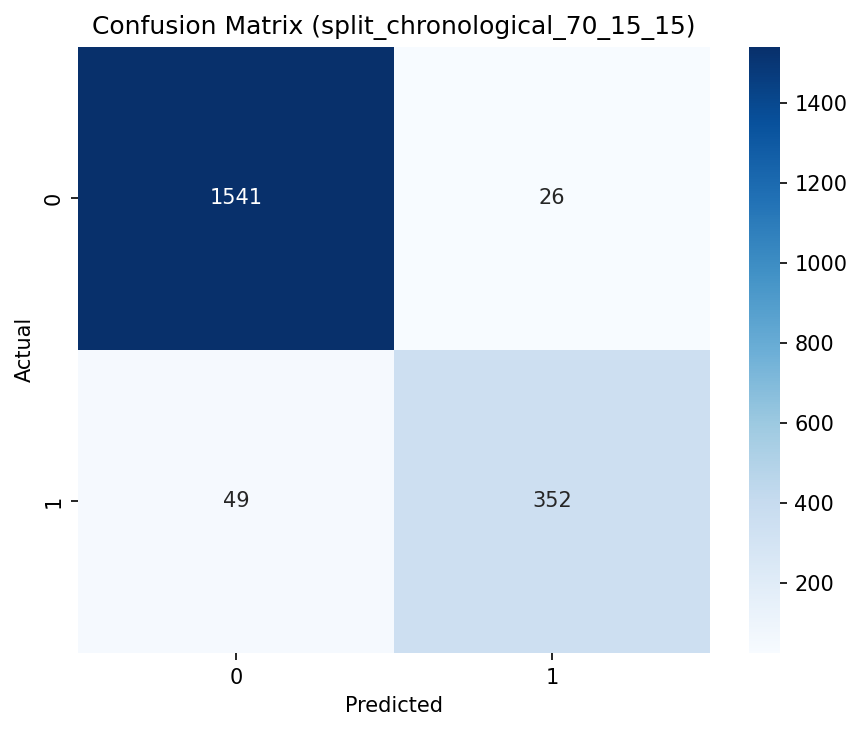

In [3]:
# Plot 1: Confusion Matrix
reports_out = os.path.join('..', '..', 'reports', 'split_chronological_70_15_15')
os.makedirs(reports_out, exist_ok=True)

cm = confusion_matrix(y_test, test_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=[0, 1], yticklabels=[0, 1])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (split_chronological_70_15_15)')
plt.tight_layout()
plt.savefig(os.path.join(reports_out, 'extra_trees_model_confusion_matrix.png'), dpi=150)
plt.show()


### 4. Graph 2: Receiver Operating Characteristic (ROC) Curve


<string>:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown



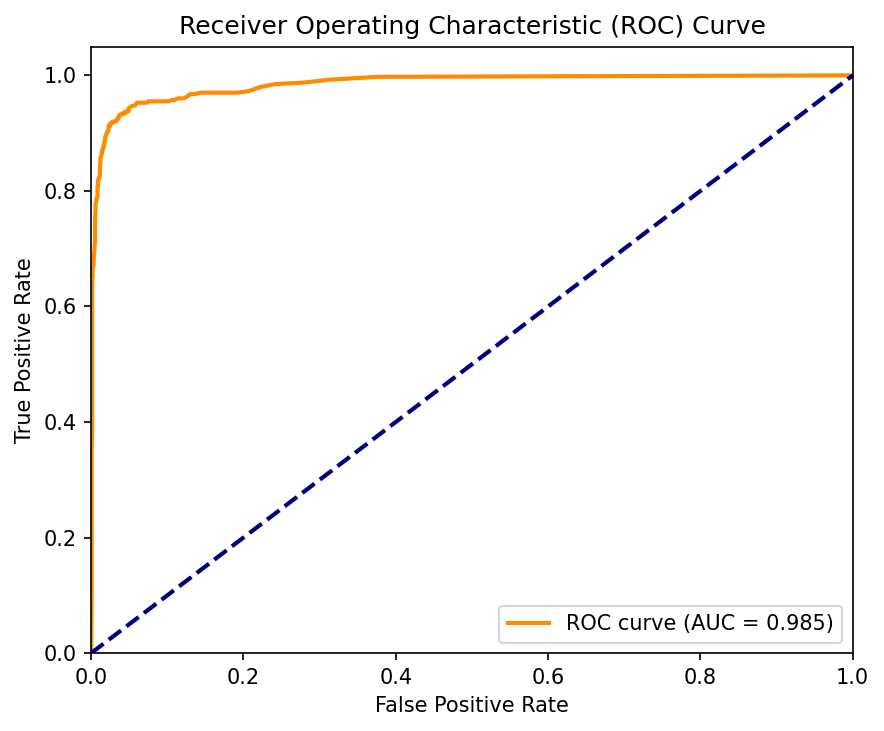

In [4]:
# Plot 2: Receiver Operating Characteristic (ROC) Curve
reports_out = os.path.join('..', '..', 'reports', 'split_chronological_70_15_15')
fpr, tpr, _ = roc_curve(y_test, test_probs)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(reports_out, 'extra_trees_model_roc_curve.png'), dpi=150)
plt.show()


### 5. Graph 3: Predicted Probability Distribution


<string>:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown



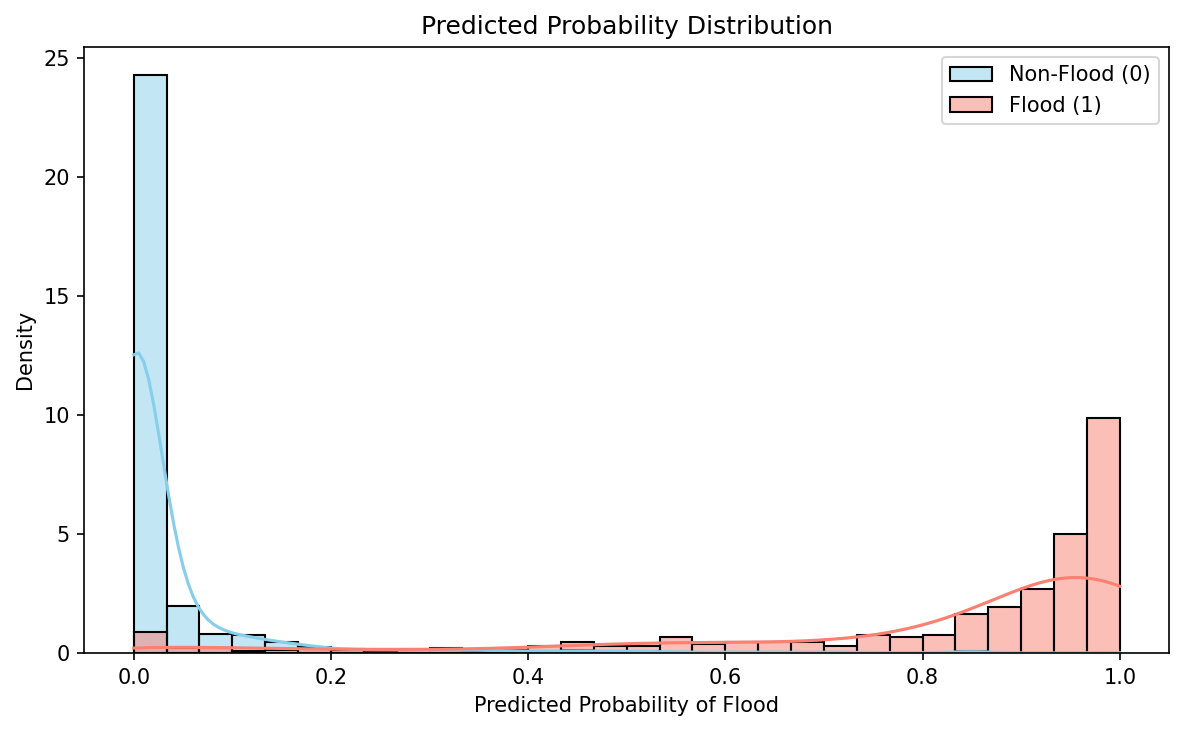

In [5]:
# Plot 3: Predicted Probability Distribution
reports_out = os.path.join('..', '..', 'reports', 'split_chronological_70_15_15')
plt.figure(figsize=(8, 5))
sns.histplot(test_probs[y_test == 0], color='skyblue', label='Non-Flood (0)', bins=30, stat='density', kde=True)
sns.histplot(test_probs[y_test == 1], color='salmon', label='Flood (1)', bins=30, stat='density', kde=True)
plt.xlabel('Predicted Probability of Flood')
plt.ylabel('Density')
plt.title('Predicted Probability Distribution')
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(reports_out, 'extra_trees_model_probability_distribution.png'), dpi=150)
plt.show()


### 6. Graph 4: Top 15 Feature Importances


<string>:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown



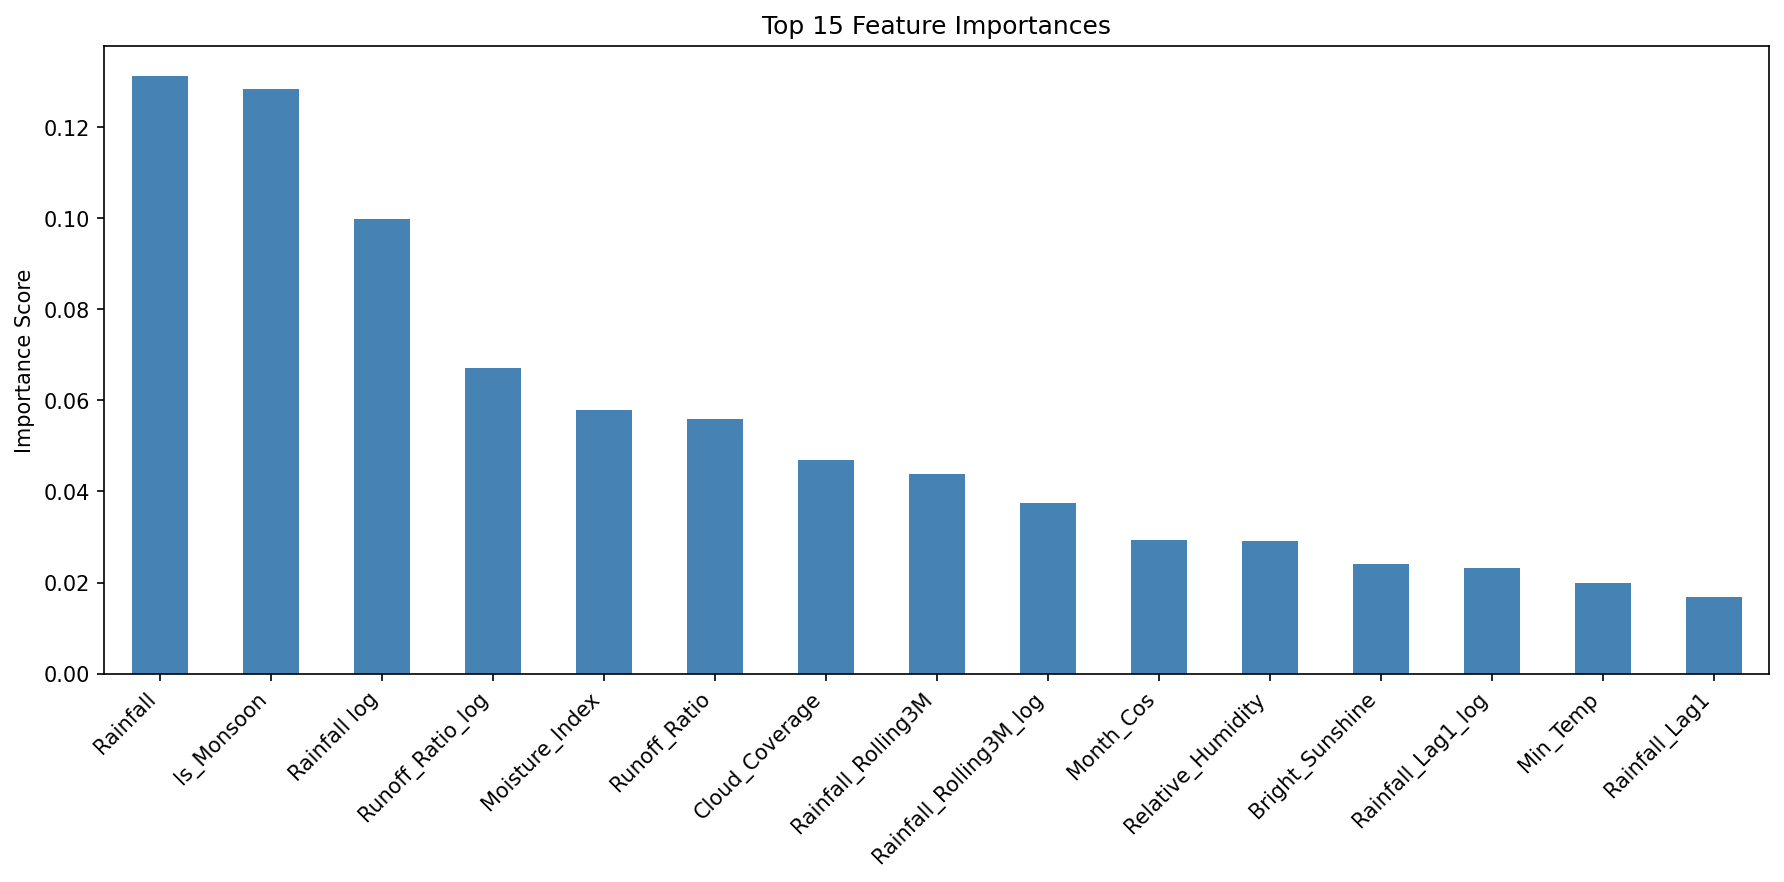

In [6]:
# Plot 4: Top 15 Feature Importances
reports_out = os.path.join('..', '..', 'reports', 'split_chronological_70_15_15')
importances = pd.Series(model.feature_importances_, index=feature_cols).sort_values(ascending=False)
plt.figure(figsize=(12, 6))
importances[:15].plot(kind='bar', color='steelblue')
plt.title('Top 15 Feature Importances')
plt.ylabel('Importance Score')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(reports_out, 'extra_trees_model_feature_importance.png'), dpi=150)
plt.show()
